In [1]:
import pandas as pd
import numpy as np

# Указываем полный путь к файлу (префикс r защищает от ошибок с обратными слешами)
file_path = r"C:\Users\User\rstudio-docker\Pharma_clean_1.csv"

# Пытаемся загрузить файл
try:
    df = pd.read_csv(file_path)
    print("Файл успешно загружен!\n")
except FileNotFoundError:
    print("ОШИБКА: Файл не найден. Проверьте путь и название файла.")
    raise
except Exception as e:
    print(f"Произошла ошибка при чтении: {e}")
    raise

# ШАГ 6: Проверяем размерность (сколько строк и столбцов)
print("Размерность данных (строки, столбцы):")
print(df.shape)
print("\n" + "-"*40 + "\n")

# ШАГ 7: Смотрим первые и последние строки
print("Первые 5 строк:")
print(df.head())
print("\n" + "-"*40 + "\n")

print("Последние 5 строк:")
print(df.tail())

Файл успешно загружен!

Размерность данных (строки, столбцы):
(2106, 12)

----------------------------------------

Первые 5 строк:
       Дата  НПВС пр. уксус  НПВС пр. проп  Салиц. к-та  Парацетамол  \
0  1/2/2014               0              4            3           32   
1  1/3/2014               8              4            4           51   
2  1/4/2014               2              1            6           62   
3  1/5/2014               4              3            7           41   
4  1/6/2014               5              1            4           22   

   Психолепт/успокоит  Снотворн/седавтивн  Противоастмат/противокашл  \
0                   7                   0                          0   
1                  16                   0                         20   
2                  10                   0                          9   
3                   8                   0                          3   
4                  16                   2                          6   

  

In [2]:
# ШАГ 8: Изучаем типы данных до преобразования
print("Типы данных до преобразования:")
df.info()
print("\n" + "-"*40 + "\n")

# ШАГ 9: Стандартизация названий столбцов
# Приводим к нижнему регистру, заменяем пробелы, слэши, точки и дефисы на нижние подчеркивания
df.columns = (df.columns.str.strip()
              .str.lower()
              .str.replace(' ', '_')
              .str.replace('/', '_')
              .str.replace('.', '_')
              .str.replace('-', '_'))

print("Новые названия столбцов (snake_case):")
print(df.columns.tolist())
print("\n" + "-"*40 + "\n")

# ШАГ 15 (часть 1): Преобразование дат и сортировка
# Преобразуем столбец 'дата' из строки в формат datetime
# Формат в файле: Месяц/День/Год (например, 1/2/2014 -> %m/%d/%Y)
df['дата'] = pd.to_datetime(df['дата'], format='%m/%d/%Y')

# Сортируем данные по дате по возрастанию, чтобы обеспечить правильную хронологию
df = df.sort_values('дата').reset_index(drop=True)

# Проверяем фактический временной охват
print("Фактический период данных:")
print(f"С {df['дата'].min().date()} по {df['дата'].max().date()}")
print("\n" + "-"*40 + "\n")

# Проверяем типы данных после преобразования
print("Типы данных после преобразования:")
df.info()

Типы данных до преобразования:
<class 'pandas.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Дата                       2106 non-null   str  
 1   НПВС пр. уксус             2106 non-null   int64
 2   НПВС пр. проп              2106 non-null   int64
 3   Салиц. к-та                2106 non-null   int64
 4   Парацетамол                2106 non-null   int64
 5   Психолепт/успокоит         2106 non-null   int64
 6   Снотворн/седавтивн         2106 non-null   int64
 7   Противоастмат/противокашл  2106 non-null   int64
 8   Антигистамин               2106 non-null   int64
 9   Год                        2106 non-null   int64
 10  Месяц                      2106 non-null   int64
 11  День_Недели                2106 non-null   str  
dtypes: int64(10), str(2)
memory usage: 230.6 KB

----------------------------------------

Новые названия столбцов (

In [3]:
# ШАГ 10: Проверка явных пропусков (NaN)
#  давайте проверим 
print("Количество пропусков (NaN) в каждом столбце:")
print(df.isna().sum())
print("\n" + "-"*40 + "\n")

# ШАГ 12: Проверка дубликатов
print("Количество полных дубликатов строк:")
print(df.duplicated().sum())
print("\nКоличество дубликатов по дате (должно быть 0, так как 1 строка = 1 день):")
print(df['дата'].duplicated().sum())
print("\n" + "-"*40 + "\n")

# ШАГ 11 и 20: Поиск аномалий (Дни с полным нулем)
# Фиксируем список столбцов с препаратами, используя новые snake_case названия
drug_cols = [
    'нпвс_пр__уксус', 'нпвс_пр__проп', 'салиц__к_та', 'парацетамол',
    'психолепт_успокоит', 'снотворн_седавтивн', 
    'противоастмат_противокашл', 'антигистамин'
]

# Создаем флаг-признак: True, если во всех 8 колонках с препаратами стоит 0
df['is_all_zeros'] = (df[drug_cols] == 0).all(axis=1)

# Считаем количество таких дней
zero_days_count = df['is_all_zeros'].sum()
print(f"Количество дней с нулевыми продажами по всем 8 группам: {zero_days_count}")
print("\nПримеры таких дат (первые 10):")
print(df[df['is_all_zeros']][['дата', 'день_недели']].head(10))
print("\n" + "-"*40 + "\n")

# ШАГ 13: Базовая статистика по числовым столбцам (препараты)
# Это поможет нам увидеть минимальные, максимальные и средние значения
print("Описательная статистика по препаратам:")
print(df[drug_cols].describe())

Количество пропусков (NaN) в каждом столбце:
дата                         0
нпвс_пр__уксус               0
нпвс_пр__проп                0
салиц__к_та                  0
парацетамол                  0
психолепт_успокоит           0
снотворн_седавтивн           0
противоастмат_противокашл    0
антигистамин                 0
год                          0
месяц                        0
день_недели                  0
dtype: int64

----------------------------------------

Количество полных дубликатов строк:
0

Количество дубликатов по дате (должно быть 0, так как 1 строка = 1 день):
0

----------------------------------------

Количество дней с нулевыми продажами по всем 8 группам: 26

Примеры таких дат (первые 10):
          дата день_недели
5   2014-01-07     Tuesday
108 2014-04-20      Sunday
119 2014-05-01    Thursday
351 2014-12-19      Friday
364 2015-01-01    Thursday
370 2015-01-07   Wednesday
465 2015-04-12      Sunday
716 2015-12-19    Saturday
729 2016-01-01      Friday
735 2016

In [4]:
# ШАГ 14: Проверка категориального столбца 'день_недели'
print("Распределение количества дней по дням недели:")
print(df['день_недели'].value_counts())
print("\n" + "-"*40 + "\n")

# ШАГ 15 (Gap Analysis): Проверка непрерывности временного ряда
# Создаем эталонный календарь от первой до последней даты в датасете
full_date_range = pd.date_range(start=df['дата'].min(), end=df['дата'].max(), freq='D')

# Ищем даты, которые есть в календаре, но отсутствуют в нашем датасете
missing_dates = full_date_range.difference(df['дата'])

print(f"Ожидаемое количество дней в периоде (календарь): {len(full_date_range)}")
print(f"Фактическое количество строк в датасете: {len(df)}")
print(f"Количество пропущенных дней (разрывов в данных): {len(missing_dates)}")

if len(missing_dates) > 0:
    print("\nСписок пропущенных дат (первые 15):")
    print(missing_dates[:15])
else:
    print("\nВременной ряд абсолютно непрерывен, пропусков дат нет.")
print("\n" + "-"*40 + "\n")

# ШАГ 16: Создание производных признаков для анализа гипотез
# Извлекаем квартал и день месяца
df['квартал'] = df['дата'].dt.quarter
df['день_месяца'] = df['дата'].dt.day

# Создаем признак 'Сезон' для проверки Гипотезы 2 (Зима vs Лето)
def get_season(month):
    if month in [12, 1, 2]: return 'Зима'
    if month in [3, 4, 5]: return 'Весна'
    if month in [6, 7, 8]: return 'Лето'
    return 'Осень'

df['сезон'] = df['месяц'].apply(get_season)

# Создаем флаг выходного дня (Суббота и Воскресенье = 1, Будни = 0)
# Это понадобится для проверки Гипотезы 3 (недельные паттерны)
df['is_weekend'] = df['день_недели'].isin(['Saturday', 'Sunday']).astype(int)

print("Пример данных с новыми производными признаками:")
print(df[['дата', 'день_недели', 'is_weekend', 'месяц', 'сезон', 'квартал']].head(10))

Распределение количества дней по дням недели:
день_недели
Thursday     301
Friday       301
Saturday     301
Sunday       301
Monday       301
Tuesday      301
Wednesday    300
Name: count, dtype: int64

----------------------------------------

Ожидаемое количество дней в периоде (календарь): 2106
Фактическое количество строк в датасете: 2106
Количество пропущенных дней (разрывов в данных): 0

Временной ряд абсолютно непрерывен, пропусков дат нет.

----------------------------------------

Пример данных с новыми производными признаками:
        дата день_недели  is_weekend  месяц сезон  квартал
0 2014-01-02    Thursday           0      1  Зима        1
1 2014-01-03      Friday           0      1  Зима        1
2 2014-01-04    Saturday           1      1  Зима        1
3 2014-01-05      Sunday           1      1  Зима        1
4 2014-01-06      Monday           0      1  Зима        1
5 2014-01-07     Tuesday           0      1  Зима        1
6 2014-01-08   Wednesday           0      1

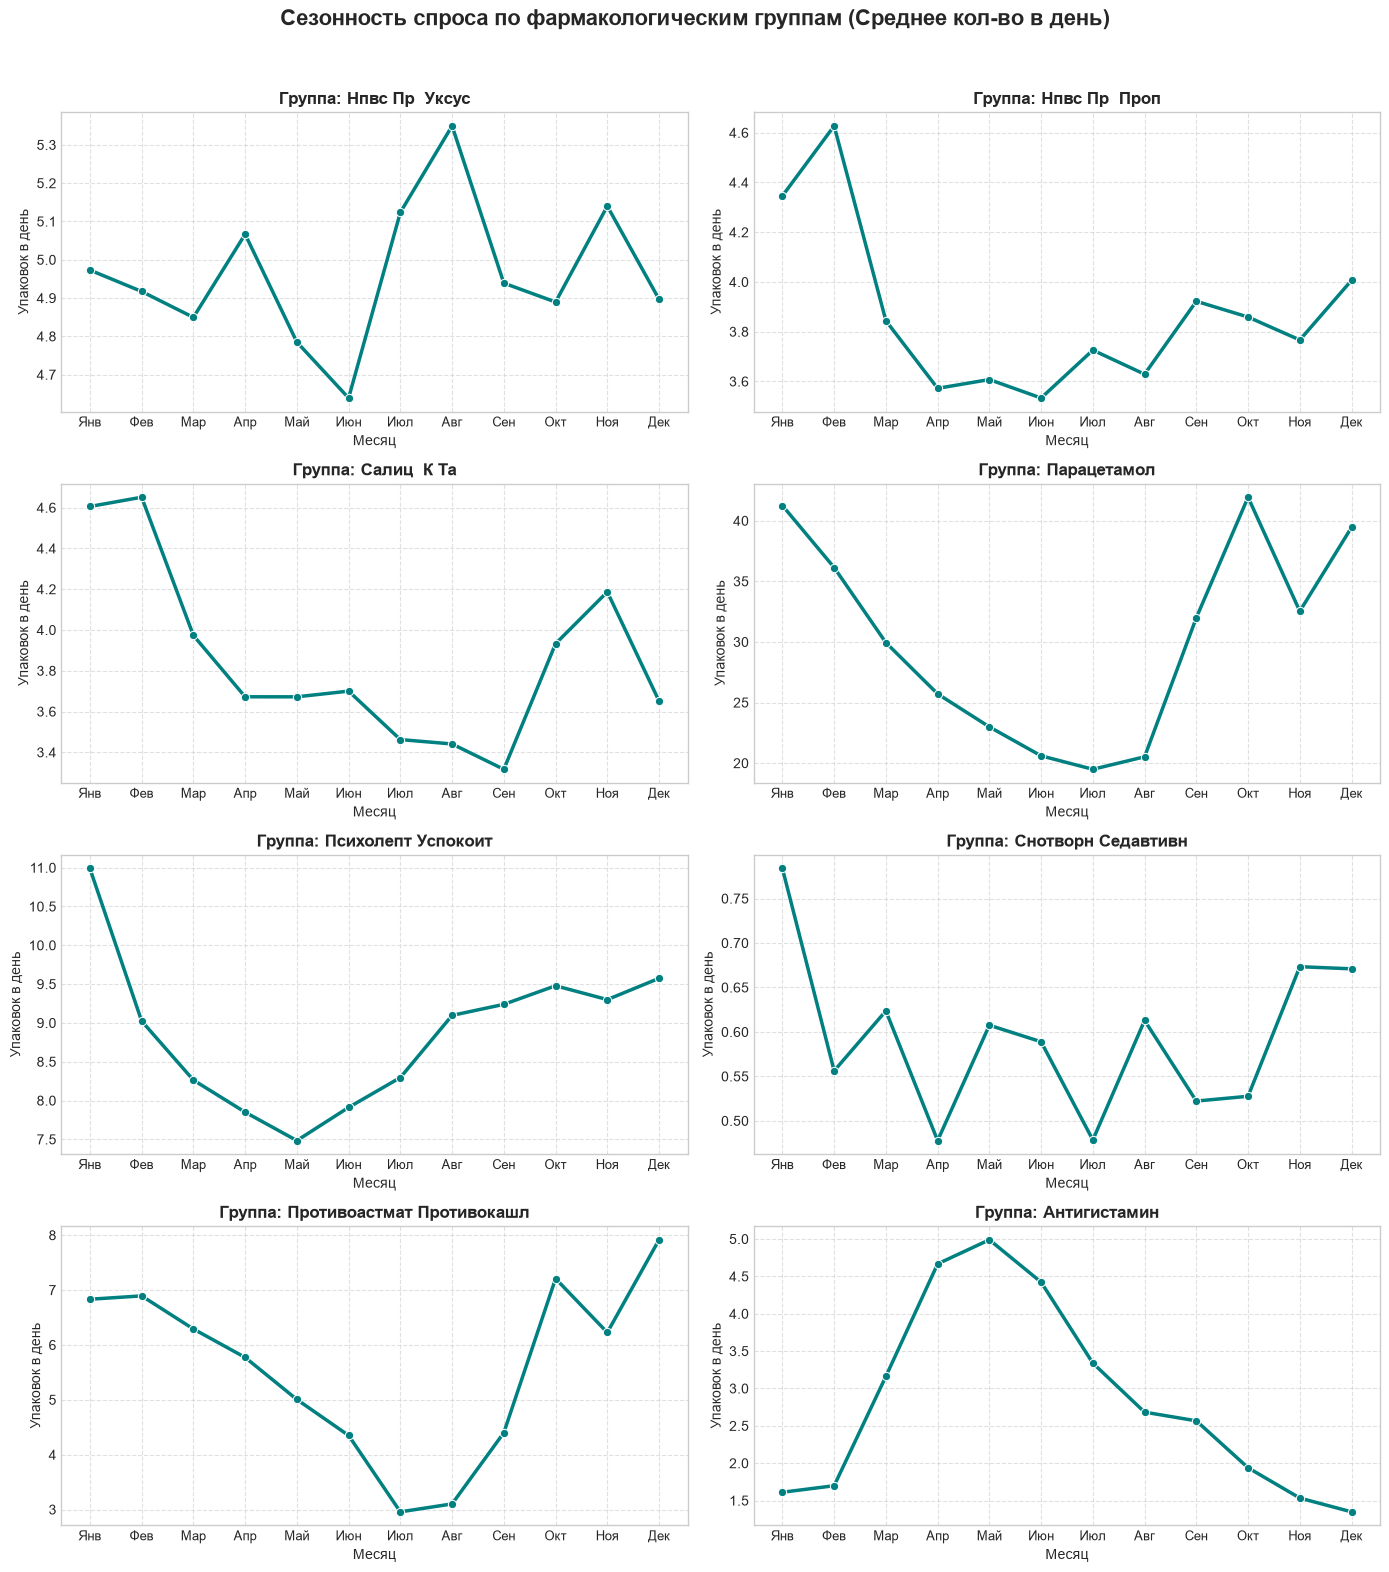

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Настраиваем стиль графиков
plt.style.use('seaborn-v0_8-whitegrid')

# ШАГ 17/19: Агрегация и визуализация сезонности (Сетка графиков)
# 1. Считаем средние продажи для каждого месяца по всем 8 категориям
# Используем наш список drug_cols и столбец 'месяц'
monthly_data = df.groupby('месяц')[drug_cols].mean().reset_index()

# 2. Создаем сетку графиков: 4 ряда по 2 колонки
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 16))
fig.suptitle('Сезонность спроса по фармакологическим группам (Среднее кол-во в день)', 
             fontsize=16, fontweight='bold', y=0.98)

# Сглаживаем сетку осей в один плоский список для удобства работы в цикле
axes_flat = axes.flatten()

# Словарь для замены номеров месяцев на сокращения (для читаемости оси X)
month_labels = {1: 'Янв', 2: 'Фев', 3: 'Мар', 4: 'Апр', 5: 'Май', 6: 'Июн', 
                7: 'Июл', 8: 'Авг', 9: 'Сен', 10: 'Окт', 11: 'Ноя', 12: 'Дек'}

# 3. Циклом строим график для каждого препарата в своем окошке
for i, col in enumerate(drug_cols):
    ax = axes_flat[i]
    
    # Строим линейный график
    sns.lineplot(data=monthly_data, x='месяц', y=col, marker='o', 
                 color='teal', linewidth=2.5, ax=ax)
    
    # Настраиваем заголовок и подписи для каждого отдельного графика
    # .replace('_', ' ').title() делает snake_case название более читаемым
    ax.set_title(f'Группа: {col.replace("_", " ").title()}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Месяц', fontsize=10)
    ax.set_ylabel('Упаковок в день', fontsize=10)
    
    # Показываем все 12 месяцев и заменяем цифры на названия месяцев
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([month_labels[m] for m in range(1, 13)], fontsize=9)
    
    # Добавляем сетку для удобства чтения
    ax.grid(True, linestyle='--', alpha=0.6)

# Настраиваем аккуратные отступы между окошками, чтобы названия не накладывались
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

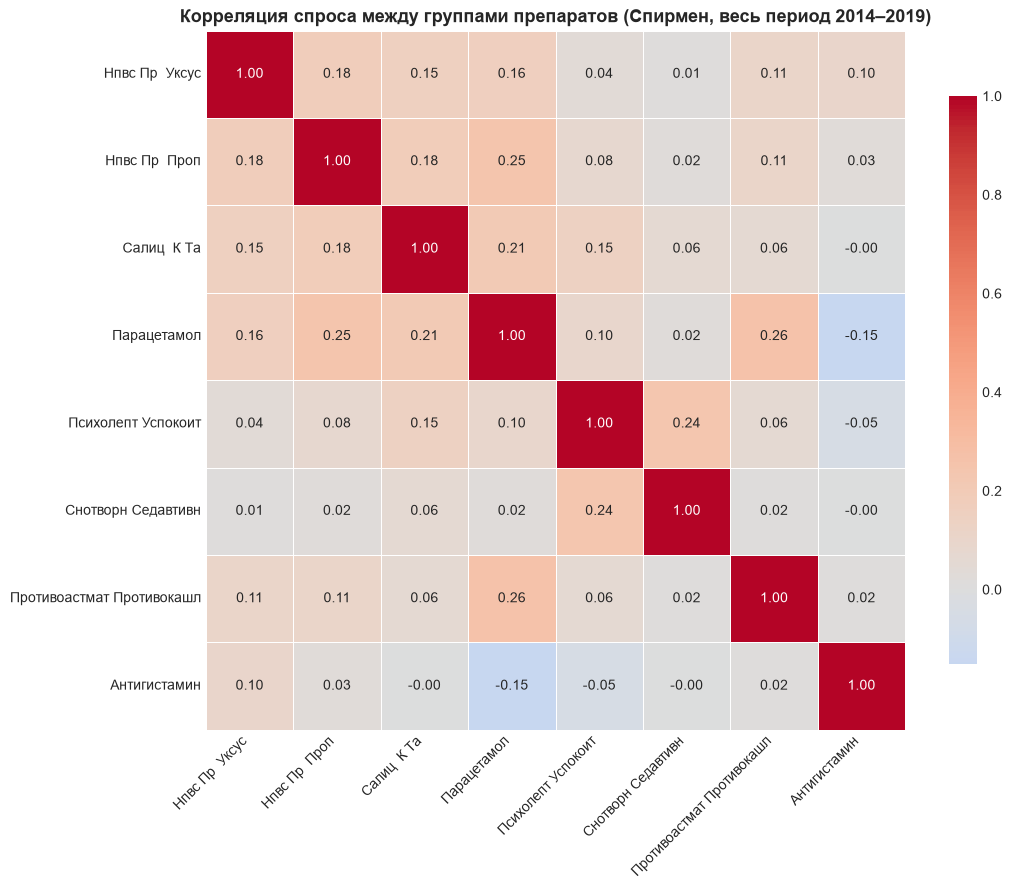

САМЫЕ СИЛЬНЫЕ СВЯЗИ МЕЖДУ ГРУППАМИ:
------------------------------------------------------------

Топ-5 положительных корреляций:
  парацетамол <-> противоастмат_противокашл: r = 0.26
  нпвс_пр__проп <-> парацетамол: r = 0.25
  психолепт_успокоит <-> снотворн_седавтивн: r = 0.24
  салиц__к_та <-> парацетамол: r = 0.21
  нпвс_пр__проп <-> салиц__к_та: r = 0.18

Топ-3 отрицательных корреляций:
  парацетамол <-> антигистамин: r = -0.15
  психолепт_успокоит <-> антигистамин: r = -0.05
  салиц__к_та <-> антигистамин: r = -0.00


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# ШАГ 17: Тепловая карта корреляций между фармакологическими группами
# Используем корреляцию Спирмена (устойчива к выбросам, работает с рангами)
corr_matrix = df[drug_cols].corr(method='spearman')

# Читаемые подписи для осей (заменяем подчеркивания на пробелы)
labels = [col.replace('_', ' ').title() for col in drug_cols]

plt.figure(figsize=(11, 9))
sns.heatmap(
    corr_matrix, 
    annot=True,               # Показываем значения коэффициентов в ячейках
    cmap='coolwarm',          # Синий = отрицательная, красный = положительная связь
    center=0,                 # Центрируем шкалу на нуле
    fmt='.2f',                # Формат чисел: 2 знака после запятой
    square=True,              # Квадратные ячейки
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    xticklabels=labels,
    yticklabels=labels
)
plt.title('Корреляция спроса между группами препаратов (Спирмен, весь период 2014–2019)', 
          fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

# ==============================================================================
# ДОПОЛНИТЕЛЬНО: Выводим самые сильные связи текстом (для протокола анализа)
# ==============================================================================
print("САМЫЕ СИЛЬНЫЕ СВЯЗИ МЕЖДУ ГРУППАМИ:")
print("-" * 60)

# Собираем уникальные пары и их коэффициенты
pairs = []
for i, col1 in enumerate(drug_cols):
    for col2 in drug_cols[i+1:]:
        pairs.append((col1, col2, corr_matrix.loc[col1, col2]))

# Топ-5 положительных связей
print("\nТоп-5 положительных корреляций:")
for c1, c2, r in sorted(pairs, key=lambda x: x[2], reverse=True)[:5]:
    print(f"  {c1} <-> {c2}: r = {r:.2f}")

# Топ-3 отрицательных связей
print("\nТоп-3 отрицательных корреляций:")
for c1, c2, r in sorted(pairs, key=lambda x: x[2])[:3]:
    print(f"  {c1} <-> {c2}: r = {r:.2f}")

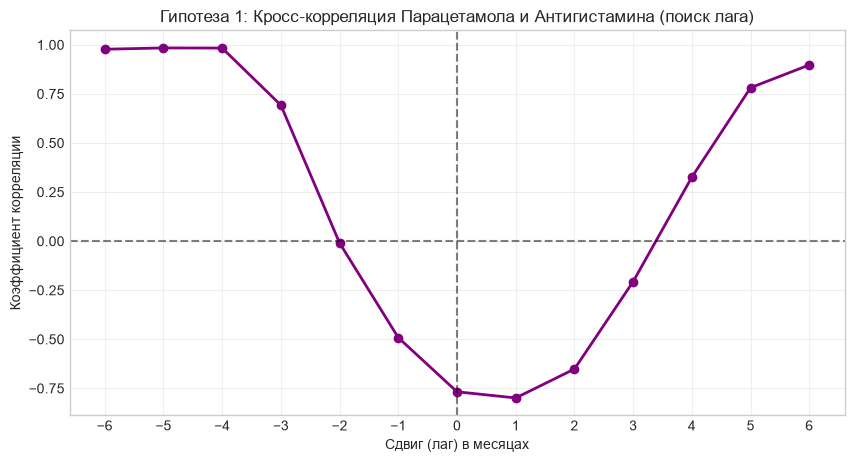

МАКСИМАЛЬНАЯ ПРОТИВОФАЗА (Гипотеза 1):
Сдвиг: 1 месяцев
Корреляция при этом сдвиге: -0.80

------------------------------------------------------------



C:\Users\User\AppData\Local\Temp\ipykernel_44924\3472844921.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_h2, x='Сезон', y='Корреляция', palette='coolwarm')


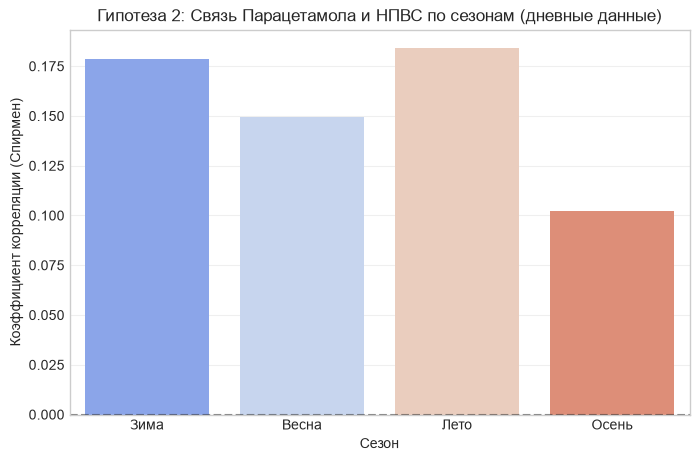

Таблица корреляций по сезонам (Гипотеза 2):
   Сезон  Корреляция
0   Зима    0.178357
1  Весна    0.149520
2   Лето    0.184206
3  Осень    0.102132


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# БЛОК 1. Гипотеза 1: Поиск точного временного сдвига (лага)
# ==============================================================================
# Пересчитываем среднемесячные значения, чтобы сгладить дневной шум
monthly_trend = df.groupby('месяц')[['парацетамол', 'антигистамин']].mean()

# Мы будем сдвигать ряд Антигистамина относительно Парацетамола 
# и смотреть, при каком сдвиге отрицательная корреляция станет максимальной.
lags = range(-6, 7) # сдвиг от -6 до +6 месяцев
correlations = []

for lag in lags:
    # Сдвигаем антигистамин на lag месяцев
    shifted_antihist = monthly_trend['антигистамин'].shift(lag)
    # Считаем корреляцию Пирсона для месячных профилей
    corr = monthly_trend['парацетамол'].corr(shifted_antihist)
    correlations.append({'lag_месяцев': lag, 'корреляция': corr})

df_lags = pd.DataFrame(correlations)

# Визуализация кросс-корреляции
plt.figure(figsize=(10, 5))
plt.plot(df_lags['lag_месяцев'], df_lags['корреляция'], marker='o', color='purple', linewidth=2)
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.axvline(0, color='black', linestyle='--', alpha=0.5)
plt.title('Гипотеза 1: Кросс-корреляция Парацетамола и Антигистамина (поиск лага)')
plt.xlabel('Сдвиг (лаг) в месяцах')
plt.ylabel('Коэффициент корреляции')
plt.xticks(lags)
plt.grid(True, alpha=0.3)
plt.show()

# Находим лаг с максимальной отрицательной корреляцией (сильнейшая противофаза)
min_corr_row = df_lags.loc[df_lags['корреляция'].idxmin()]
print(f"МАКСИМАЛЬНАЯ ПРОТИВОФАЗА (Гипотеза 1):")
print(f"Сдвиг: {int(min_corr_row['lag_месяцев'])} месяцев")
print(f"Корреляция при этом сдвиге: {min_corr_row['корреляция']:.2f}")
print("\n" + "-"*60 + "\n")

# ==============================================================================
# БЛОК 2. Гипотеза 2: Анальгетики (Зима vs Лето)
# ==============================================================================
# Чтобы увидеть реальные совместные покупки, берем дневные данные.
# Исключаем дни, когда аптека не работала (is_all_zeros == True), чтобы они не искажали картину.
df_active = df[df['is_all_zeros'] == False].copy()

# Считаем корреляцию Спирмена для каждого сезона отдельно
seasons = ['Зима', 'Весна', 'Лето', 'Осень']
results_h2 = []

for season in seasons:
    season_data = df_active[df_active['сезон'] == season]
    # Считаем корреляцию между Парацетамолом и НПВС (уксусная к-та)
    corr = season_data['парацетамол'].corr(season_data['нпвс_пр__уксус'], method='spearman')
    results_h2.append({'Сезон': season, 'Корреляция': corr})
    
df_h2 = pd.DataFrame(results_h2)

# Визуализация
plt.figure(figsize=(8, 5))
sns.barplot(data=df_h2, x='Сезон', y='Корреляция', palette='coolwarm')
plt.title('Гипотеза 2: Связь Парацетамола и НПВС по сезонам (дневные данные)')
plt.ylabel('Коэффициент корреляции (Спирмен)')
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.grid(axis='y', alpha=0.3)
plt.show()

print("Таблица корреляций по сезонам (Гипотеза 2):")
print(df_h2)

In [8]:
# Импортируем все необходимые библиотеки для текущего блока
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

Средние продажи по дням недели:
    психолепт_успокоит  снотворн_седавтивн
Пн                9.25                0.61
Вт                9.62                0.73
Ср               10.13                0.65
Чт                8.72                0.51
Пт                9.90                0.76
Сб                8.57                0.55
Вс                5.80                0.33

------------------------------------------------------------



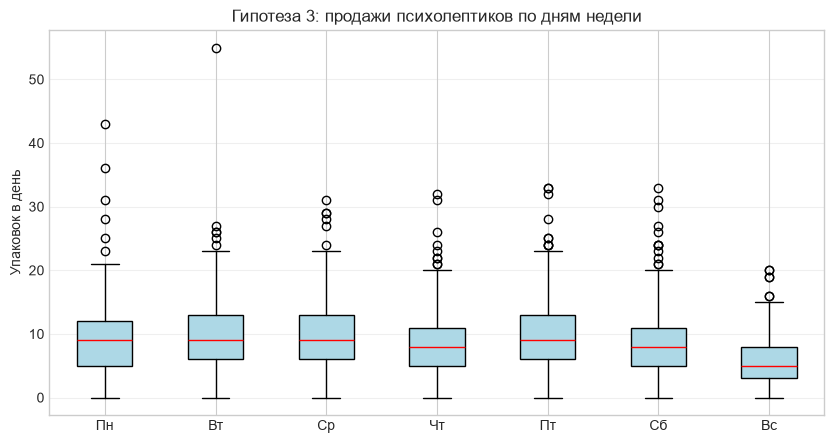

Тест Краскела-Уоллиса (все данные):
  Психолептики: p-value = 0.0000
  Снотворные:   p-value = 0.0002

Тест Краскела-Уоллиса (без нулевых дней):
  Психолептики: p-value = 0.0000

Контраст Вс+Пн против Ср+Чт (Манна-Уитни, направленный):
  Психолептики: среднее Вс+Пн = 7.52, среднее Ср+Чт = 9.42, p-value = 1.0000
  Снотворные: среднее Вс+Пн = 0.47, среднее Ср+Чт = 0.58, p-value = 0.9640

Порог значимости: 0.05. Мы делаем 4 теста, поэтому с поправкой Бонферрони
строгий порог = 0.05 / 4 = 0.0125. Сравнивайте p-value с обоими порогами.


In [10]:
from scipy import stats

# ==============================================================================
# БЛОК 3. Гипотеза 3: Недельные паттерны психолептиков и снотворных
# ==============================================================================
# Задаём порядок дней недели Пн->Вс для корректных графиков и группировок
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
days_ru = {'Monday':'Пн', 'Tuesday':'Вт', 'Wednesday':'Ср', 'Thursday':'Чт',
           'Friday':'Пт', 'Saturday':'Сб', 'Sunday':'Вс'}

df['день_недели_cat'] = pd.Categorical(df['день_недели'], categories=days_order, ordered=True)

# 1) Средние продажи по дням недели (таблица для протокола)
weekday_means = df.groupby('день_недели_cat', observed=True)[['психолепт_успокоит', 'снотворн_седавтивн']].mean()
weekday_means.index = [days_ru[d] for d in weekday_means.index]
print("Средние продажи по дням недели:")
print(weekday_means.round(2))
print("\n" + "-"*60 + "\n")

# 2) Боксплот психолептиков по дням недели
fig, ax = plt.subplots(figsize=(10, 5))
data_by_day = [g['психолепт_успокоит'].values for _, g in df.groupby('день_недели_cat', observed=True)]
ax.boxplot(data_by_day, patch_artist=True,
           boxprops=dict(facecolor='lightblue'), medianprops=dict(color='red'))
ax.set_xticklabels([days_ru[d] for d in days_order])
ax.set_title('Гипотеза 3: продажи психолептиков по дням недели')
ax.set_ylabel('Упаковок в день')
ax.grid(axis='y', alpha=0.3)
plt.show()

# 3) Тест Краскела-Уоллиса: H0 = распределения во все 7 дней недели одинаковы
groups_psy   = [g['психолепт_успокоит'].values  for _, g in df.groupby('день_недели_cat', observed=True)]
groups_sleep = [g['снотворн_седавтивн'].values for _, g in df.groupby('день_недели_cat', observed=True)]
_, p_psy   = stats.kruskal(*groups_psy)
_, p_sleep = stats.kruskal(*groups_sleep)

print("Тест Краскела-Уоллиса (все данные):")
print(f"  Психолептики: p-value = {p_psy:.4f}")
print(f"  Снотворные:   p-value = {p_sleep:.4f}")

# 4) Анализ чувствительности: тот же тест БЕЗ дней, когда аптека не работала
df_active = df[df['is_all_zeros'] == False]
groups_psy_c = [g['психолепт_успокоит'].values for _, g in df_active.groupby('день_недели_cat', observed=True)]
_, p_psy_c = stats.kruskal(*groups_psy_c)
print("\nТест Краскела-Уоллиса (без нулевых дней):")
print(f"  Психолептики: p-value = {p_psy_c:.4f}")

# 5) Точечный контраст по формулировке гипотезы: Вс+Пн vs середина недели (Ср+Чт)
# alternative='greater' проверяет направленную гипотезу: Вс+Пн БОЛЬШЕ, чем Ср+Чт
print("\nКонтраст Вс+Пн против Ср+Чт (Манна-Уитни, направленный):")
for col, name in [('психолепт_успокоит', 'Психолептики'), ('снотворн_седавтивн', 'Снотворные')]:
    a = df[df['день_недели'].isin(['Sunday', 'Monday'])][col]
    b = df[df['день_недели'].isin(['Wednesday', 'Thursday'])][col]
    _, p = stats.mannwhitneyu(a, b, alternative='greater')
    print(f"  {name}: среднее Вс+Пн = {a.mean():.2f}, среднее Ср+Чт = {b.mean():.2f}, p-value = {p:.4f}")

print("\nПорог значимости: 0.05. Мы делаем 4 теста, поэтому с поправкой Бонферрони")
print("строгий порог = 0.05 / 4 = 0.0125. Сравнивайте p-value с обоими порогами.")

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка стиля для красивых "дашбордных" графиков
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.facecolor'] = 'white'

# 1. Загрузка данных (используем ваш путь)
file_path = r"C:\Users\User\rstudio-docker\Pharma_clean_1.csv"

try:
    df = pd.read_csv(file_path)
    print("✅ Данные успешно загружены!")
except FileNotFoundError:
    print("❌ Ошибка: Файл не найден. Проверьте путь к файлу.")

# 2. Приведение названий столбцов к единому стилю (нижний регистр, без пробелов и точек)
# Это нужно, чтобы дальше код не ломался из-за пробелов в названиях
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('.', '_').str.replace('-', '_')

# 3. Быстрая проверка
print(f"Размерность данных: {df.shape}")
print("\nСписок столбцов:")
print(df.columns.tolist())

✅ Данные успешно загружены!
Размерность данных: (2106, 12)

Список столбцов:
['дата', 'нпвс_пр__уксус', 'нпвс_пр__проп', 'салиц__к_та', 'парацетамол', 'психолепт/успокоит', 'снотворн/седавтивн', 'противоастмат/противокашл', 'антигистамин', 'год', 'месяц', 'день_недели']


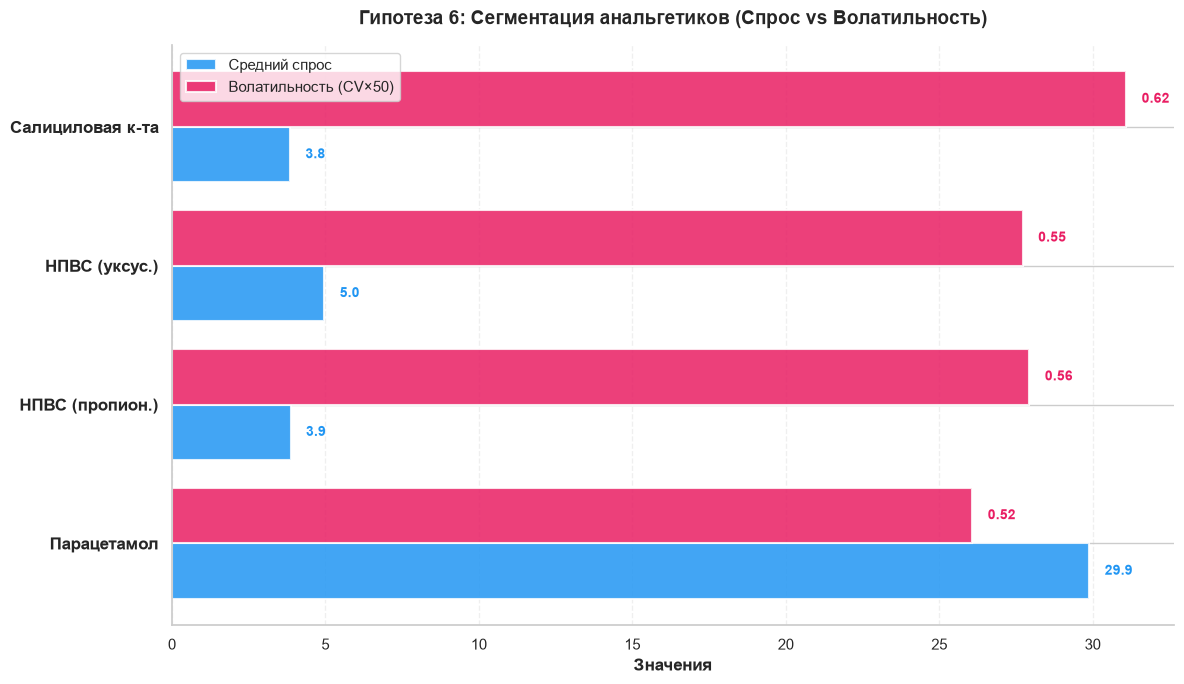

✅ График обновлён: легенда слева сверху, розовый цвет для волатильности.


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Данные
analgesics = ['парацетамол', 'нпвс_пр__проп', 'нпвс_пр__уксус', 'салиц__к_та']
names_ru = {
    'парацетамол': 'Парацетамол',
    'нпвс_пр__проп': 'НПВС (пропион.)',
    'нпвс_пр__уксус': 'НПВС (уксус.)',
    'салиц__к_та': 'Салициловая к-та'}

# 2. Считаем метрики
metrics = df[analgesics].agg(['mean', 'std']).T
metrics['cv'] = metrics['std'] / metrics['mean']
metrics['name'] = metrics.index.map(names_ru)

# 3. Красочная горизонтальная двойная столбчатая диаграмма
fig, ax1 = plt.subplots(figsize=(12, 7))

# Нормализуем CV для отображения на той же шкале, что и спрос
cv_scaled = metrics['cv'] * 50

# Столбцы для спроса (синий)
y_pos = np.arange(len(metrics))
bars1 = ax1.barh(y_pos, metrics['mean'], height=0.4, color='#2196F3', alpha=0.85, label='Средний спрос', edgecolor='white', linewidth=1.5)

# Столбцы для волатильности (РОЗОВЫЙ вместо оранжевого)
bars2 = ax1.barh(y_pos + 0.4, cv_scaled, height=0.4, color='#E91E63', alpha=0.85, label='Волатильность (CV×50)', edgecolor='white', linewidth=1.5)

# Подписи препаратов
ax1.set_yticks(y_pos + 0.2)
ax1.set_yticklabels(metrics['name'], fontsize=12, fontweight='bold')

# Значения на столбцах
for bar in bars1:
    width = bar.get_width()
    ax1.text(width + 0.5, bar.get_y() + bar.get_height()/2, f'{width:.1f}', 
             ha='left', va='center', fontsize=10, fontweight='bold', color='#2196F3')

for bar in bars2:
    width = bar.get_width()
    ax1.text(width + 0.5, bar.get_y() + bar.get_height()/2, f'{width/50:.2f}', 
             ha='left', va='center', fontsize=10, fontweight='bold', color='#E91E63')

# Оформление
ax1.set_xlabel('Значения', fontsize=12, fontweight='bold')
ax1.set_title('Гипотеза 6: Сегментация анальгетиков (Спрос vs Волатильность)', fontsize=14, fontweight='bold', pad=15)
# ЛЕГЕНДА СВЕРХУ СЛЕВА
ax1.legend(loc='upper left', fontsize=11)
ax1.grid(axis='x', alpha=0.3, linestyle='--')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

print("✅ График обновлён: легенда слева сверху, розовый цвет для волатильности.")

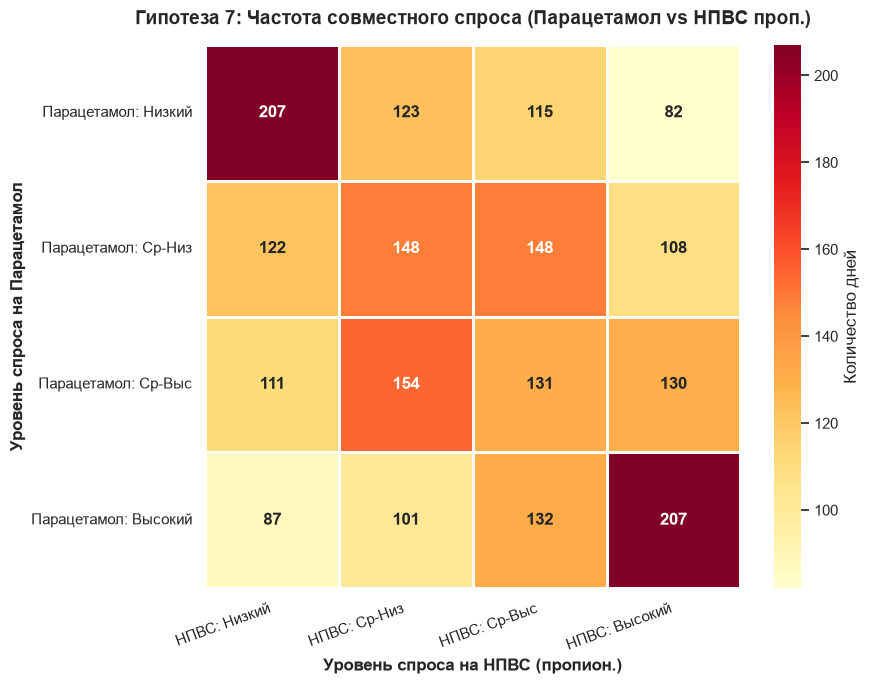

🔍 Ключевой показатель: Дней с НИЗКИМ Парацетамолом и ВЫСОКИМ НПВС = 82 (3.9% от всех дней).
💡 Если гипотеза о замещении верна, это число должно быть большим (ячейка должна быть 'горячей' и красной).


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Создаем квартили спроса (4 равные группы) с защитой от одинаковых значений
df['para_q'] = pd.qcut(df['парацетамол'].rank(method='first'), q=4, labels=['1_Низкий', '2_Ср-Низ', '3_Ср-Выс', '4_Высокий'])
df['nsaid_q'] = pd.qcut(df['нпвс_пр__проп'].rank(method='first'), q=4, labels=['1_Низкий', '2_Ср-Низ', '3_Ср-Выс', '4_Высокий'])

# 2. Строим таблицу сопряженности (сколько дней в каждой комбинации)
cross_tab = pd.crosstab(df['para_q'], df['nsaid_q'])

# Переименовываем оси для красивого отображения
cross_tab.index = ['Парацетамол: Низкий', 'Парацетамол: Ср-Низ', 'Парацетамол: Ср-Выс', 'Парацетамол: Высокий']
cross_tab.columns = ['НПВС: Низкий', 'НПВС: Ср-Низ', 'НПВС: Ср-Выс', 'НПВС: Высокий']

# 3. Красочная тепловая карта (BI-style)
plt.figure(figsize=(9, 7))
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlOrRd', linewidths=1, linecolor='white', 
            cbar_kws={'label': 'Количество дней'}, annot_kws={'size': 12, 'weight': 'bold'})

plt.title('Гипотеза 7: Частота совместного спроса (Парацетамол vs НПВС проп.)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Уровень спроса на НПВС (пропион.)', fontsize=12, fontweight='bold')
plt.ylabel('Уровень спроса на Парацетамол', fontsize=12, fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Вывод ключевого показателя для проверки гипотезы
low_para_high_nsaid = cross_tab.loc['Парацетамол: Низкий', 'НПВС: Высокий']
total_days = len(df)
percent = (low_para_high_nsaid / total_days) * 100

print(f"🔍 Ключевой показатель: Дней с НИЗКИМ Парацетамолом и ВЫСОКИМ НПВС = {low_para_high_nsaid} ({percent:.1f}% от всех дней).")
print("💡 Если гипотеза о замещении верна, это число должно быть большим (ячейка должна быть 'горячей' и красной).")

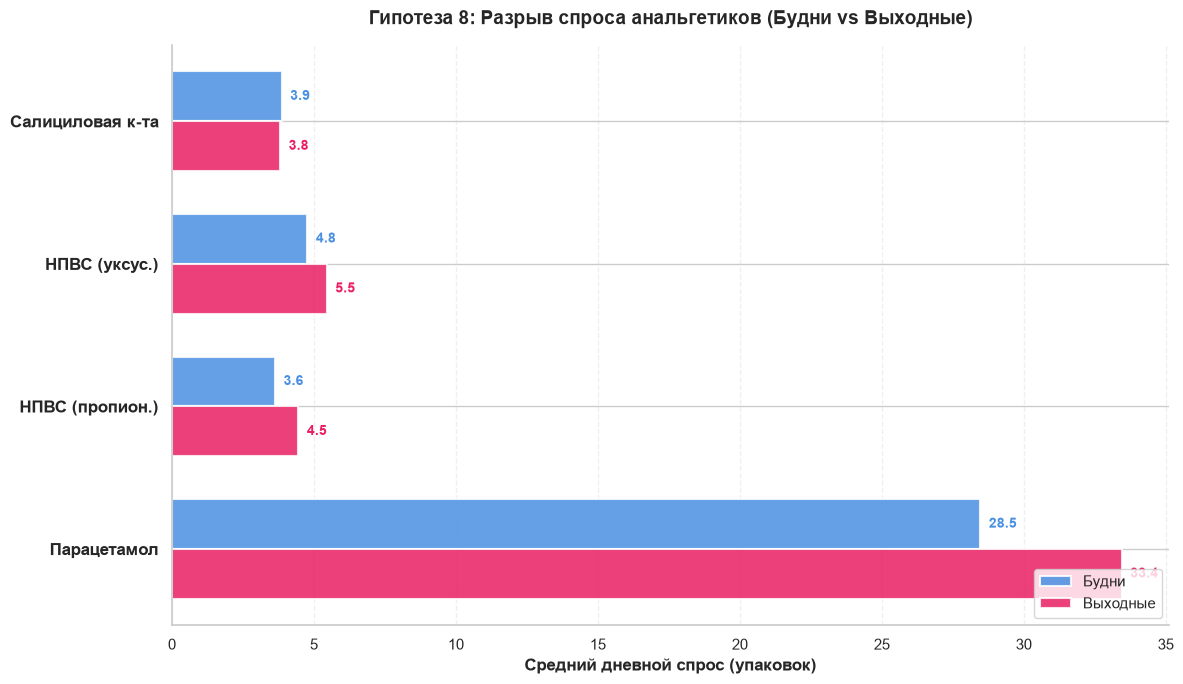

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Данные из предыдущего расчета
drugs = ['парацетамол', 'нпвс_пр__проп', 'нпвс_пр__уксус', 'салиц__к_та']
names_ru = {
    'парацетамол': 'Парацетамол',
    'нпвс_пр__проп': 'НПВС (пропион.)',
    'нпвс_пр__уксус': 'НПВС (уксус.)',
    'салиц__к_та': 'Салициловая к-та'
}

# Считаем средние продажи для будней и выходных
wd = df[df['is_weekend'] == 0][drugs].mean()
we = df[df['is_weekend'] == 1][drugs].mean()

# Создаем DataFrame для графика
plot_df = pd.DataFrame({
    'Препарат': [names_ru[col] for col in drugs],
    'Будни': [wd[col] for col in drugs],
    'Выходные': [we[col] for col in drugs]
})

# Строим горизонтальную столбчатую диаграмму
fig, ax = plt.subplots(figsize=(12, 7))

y_pos = np.arange(len(plot_df))
height = 0.35

# Столбцы для будней (синий)
bars1 = ax.barh(y_pos + height/2, plot_df['Будни'], height, 
                color='#4A90E2', alpha=0.85, label='Будни', edgecolor='white', linewidth=1.5)

# Столбцы для выходных (РОЗОВЫЙ вместо оранжевого)
bars2 = ax.barh(y_pos - height/2, plot_df['Выходные'], height, 
                color='#E91E63', alpha=0.85, label='Выходные', edgecolor='white', linewidth=1.5)

# Подписи препаратов
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['Препарат'], fontsize=12, fontweight='bold')

# Значения на столбцах
for bar in bars1:
    width = bar.get_width()
    ax.text(width + 0.3, bar.get_y() + bar.get_height()/2, f'{width:.1f}', 
            ha='left', va='center', fontsize=10, fontweight='bold', color='#4A90E2')

for bar in bars2:
    width = bar.get_width()
    ax.text(width + 0.3, bar.get_y() + bar.get_height()/2, f'{width:.1f}', 
            ha='left', va='center', fontsize=10, fontweight='bold', color='#E91E63')

# Оформление
ax.set_xlabel('Средний дневной спрос (упаковок)', fontsize=12, fontweight='bold')
ax.set_title('Гипотеза 8: Разрыв спроса анальгетиков (Будни vs Выходные)', 
             fontsize=14, fontweight='bold', pad=15)
ax.legend(loc='lower right', fontsize=11)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

✅ Данные загружены: 2106 строк


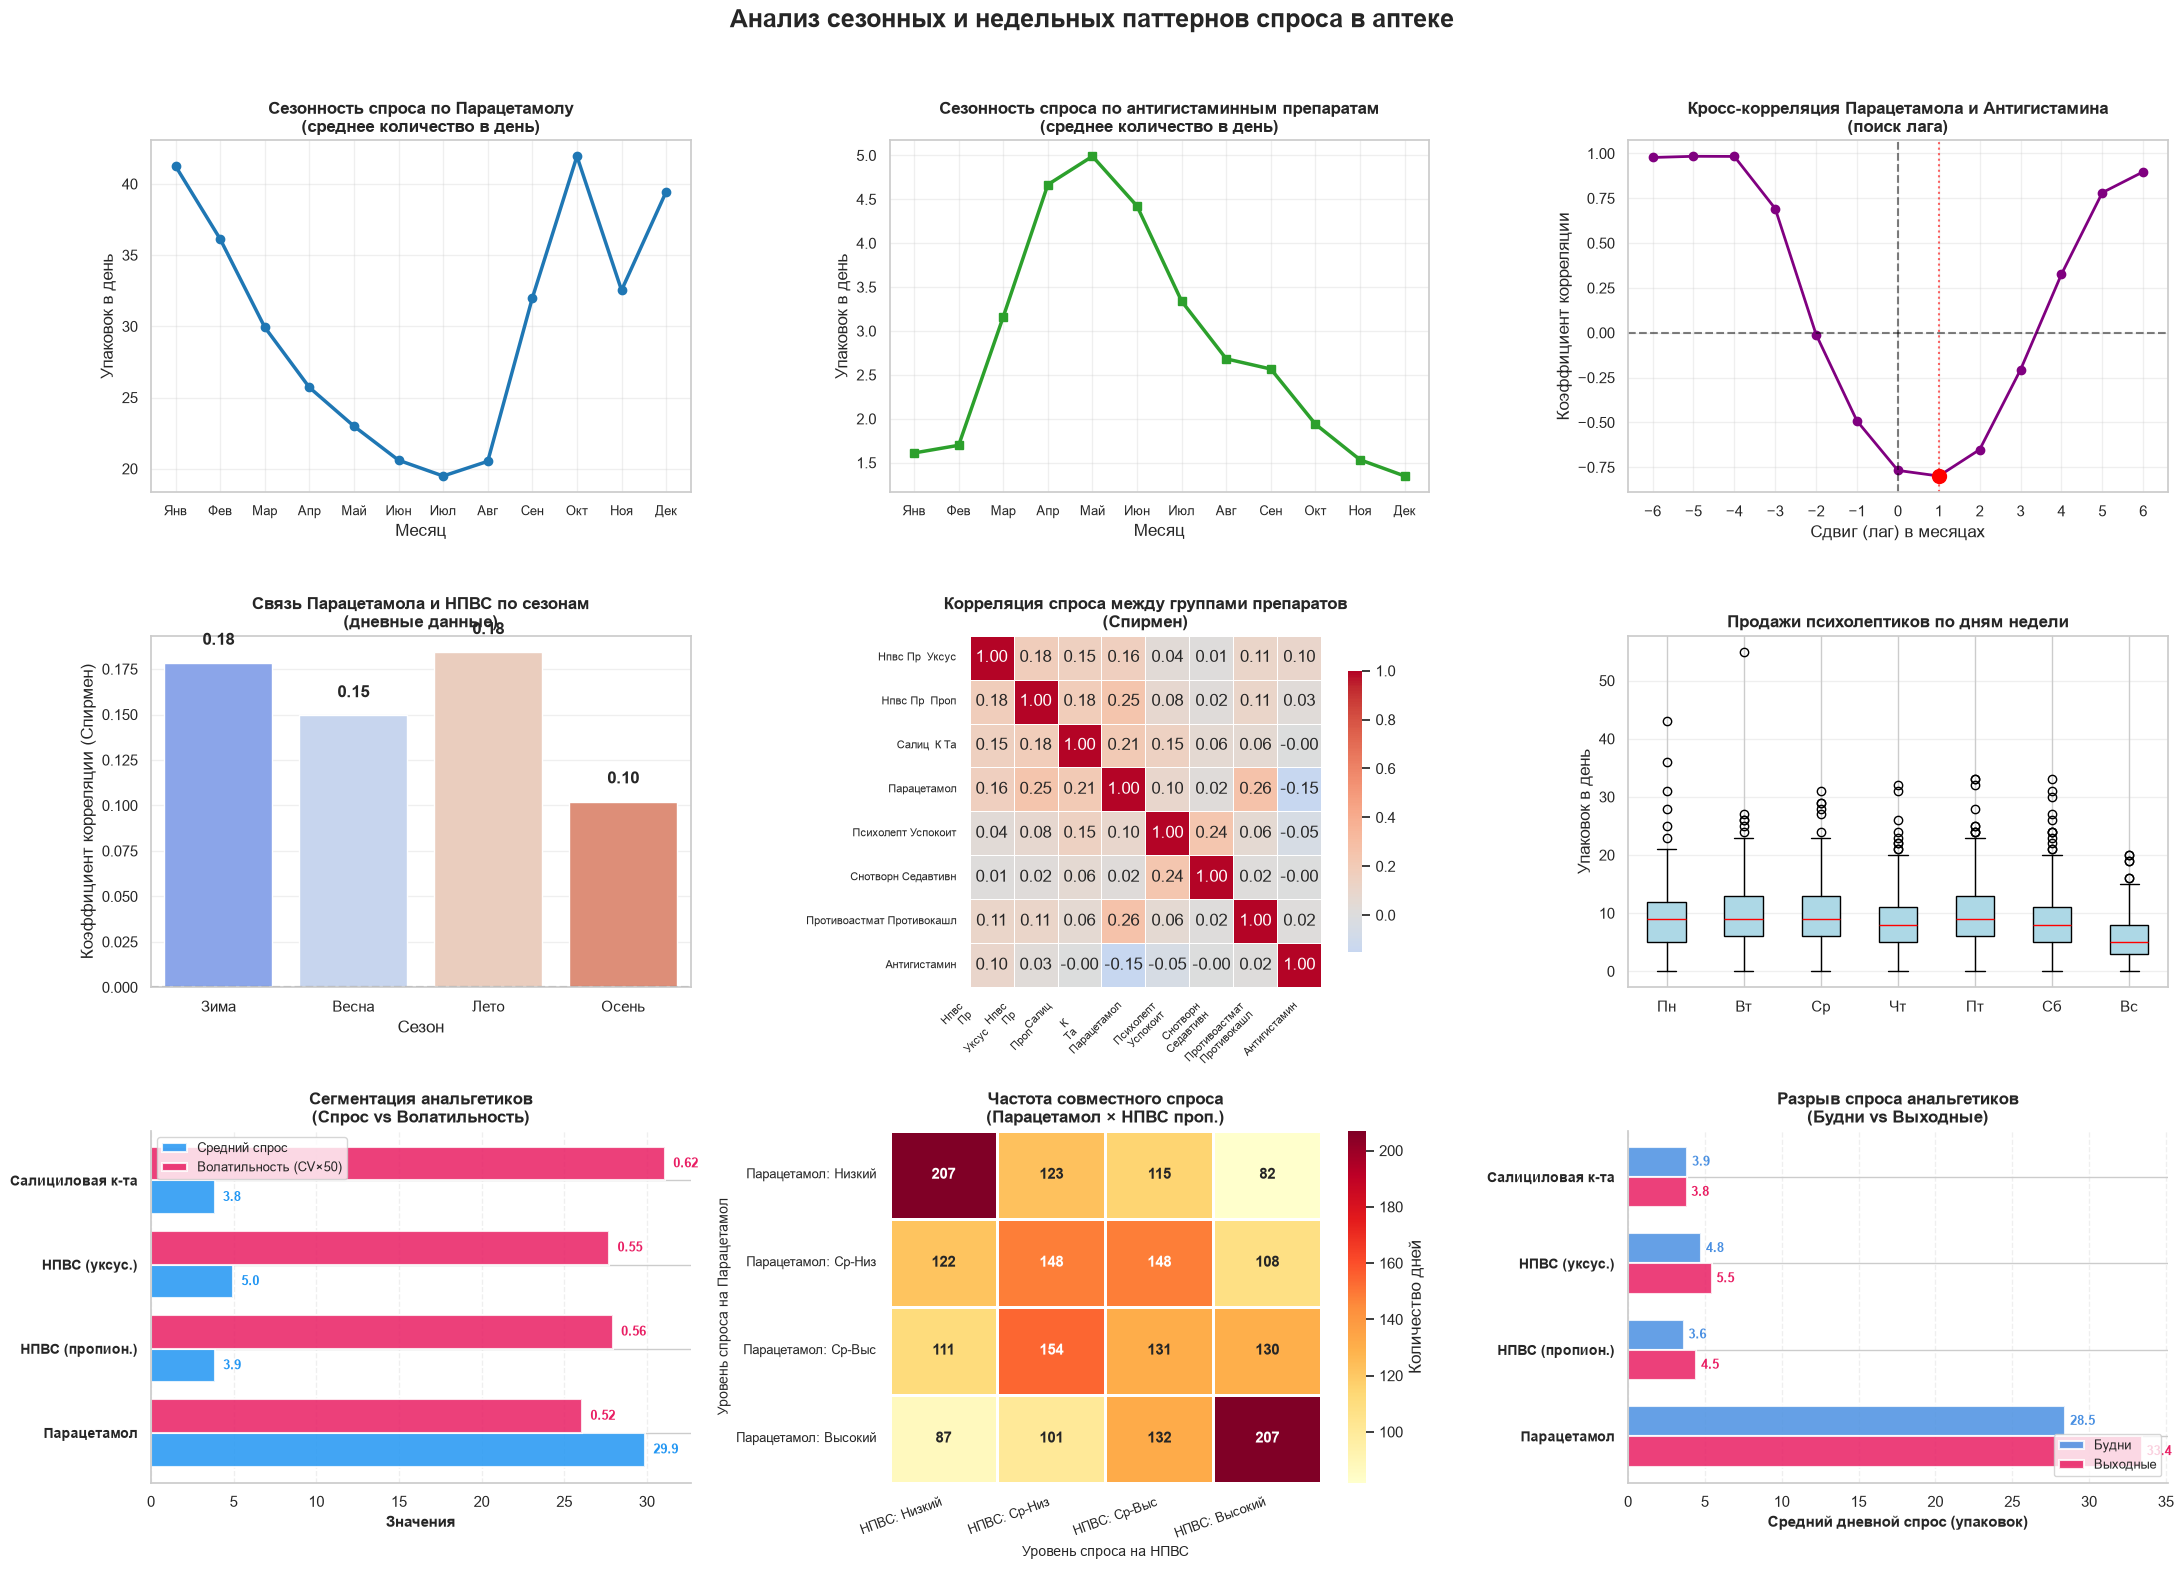

✅ Дашборд построен! Все 9 визуализаций на одном полотне (сетка 3×3).
🔍 Проверка тепловой карты Гипотезы 7: ячейка [Низкий×Низкий] = 207, ячейка [Высокий×Высокий] = 207


In [4]:
# ==============================================================================
# ЕДИНЫЙ ДАШБОРД ПО ВСЕМ ГИПОТЕЗАМ (ИСПРАВЛЕННАЯ ВЕРСИЯ)
# Сетка 3x3 — все визуализации на одном полотне
# ==============================================================================

# ==============================================================================
# БЛОК 0. ИМПОРТ БИБЛИОТЕК
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.facecolor'] = 'white'

# ==============================================================================
# БЛОК 1. ЗАГРУЗКА И ПРЕДОБРАБОТКА ДАННЫХ
# ==============================================================================
file_path = r"C:\Users\User\rstudio-docker\Pharma_clean_1.csv"
df = pd.read_csv(file_path)

# Приведение названий столбцов к snake_case
df.columns = (df.columns.str.strip()
              .str.lower()
              .str.replace(' ', '_')
              .str.replace('/', '_')
              .str.replace('.', '_')
              .str.replace('-', '_'))

# Преобразование даты
df['дата'] = pd.to_datetime(df['дата'], format='%m/%d/%Y')
df = df.sort_values('дата').reset_index(drop=True)

# Производные признаки
df['месяц'] = df['дата'].dt.month
df['год'] = df['дата'].dt.year
df['день_недели'] = df['дата'].dt.day_name()
df['квартал'] = df['дата'].dt.quarter
df['день_месяца'] = df['дата'].dt.day

# Сезон
def get_season(month):
    if month in [12, 1, 2]: return 'Зима'
    if month in [3, 4, 5]: return 'Весна'
    if month in [6, 7, 8]: return 'Лето'
    return 'Осень'
df['сезон'] = df['месяц'].apply(get_season)

# Флаг выходного дня
df['is_weekend'] = df['день_недели'].isin(['Saturday', 'Sunday']).astype(int)

# Список препаратов
drug_cols = [
    'нпвс_пр__уксус', 'нпвс_пр__проп', 'салиц__к_та', 'парацетамол',
    'психолепт_успокоит', 'снотворн_седавтивн',
    'противоастмат_противокашл', 'антигистамин'
]

# Флаг нулевых дней
df['is_all_zeros'] = (df[drug_cols] == 0).all(axis=1)

# Категориальный день недели
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
              'Friday', 'Saturday', 'Sunday']
days_ru = {'Monday': 'Пн', 'Tuesday': 'Вт', 'Wednesday': 'Ср',
           'Thursday': 'Чт', 'Friday': 'Пт', 'Saturday': 'Сб', 'Sunday': 'Вс'}
df['день_недели_cat'] = pd.Categorical(df['день_недели'],
                                       categories=days_order, ordered=True)

# Словари русских названий
names_ru = {
    'парацетамол': 'Парацетамол',
    'нпвс_пр__проп': 'НПВС (пропион.)',
    'нпвс_пр__уксус': 'НПВС (уксус.)',
    'салиц__к_та': 'Салициловая к-та',
    'антигистамин': 'Антигистамин',
    'психолепт_успокоит': 'Психолептики',
    'снотворн_седавтивн': 'Снотворные',
    'противоастмат_противокашл': 'Противоастмат.'
}

print(f"✅ Данные загружены: {df.shape[0]} строк")

# ==============================================================================
# БЛОК 2. ПОДГОТОВКА ДАННЫХ ДЛЯ ВСЕХ ГРАФИКОВ
# ==============================================================================

# --- Для Гипотезы 1: Сезонность (отдельно Парацетамол и Антигистамин) ---
monthly_para = df.groupby('месяц')['парацетамол'].mean()
monthly_antihist = df.groupby('месяц')['антигистамин'].mean()
month_labels = {1: 'Янв', 2: 'Фев', 3: 'Мар', 4: 'Апр', 5: 'Май', 6: 'Июн',
                7: 'Июл', 8: 'Авг', 9: 'Сен', 10: 'Окт', 11: 'Ноя', 12: 'Дек'}

# --- Для Гипотезы 1: Кросс-корреляция с лагами ---
monthly_trend = df.groupby('месяц')[['парацетамол', 'антигистамин']].mean()
lags = range(-6, 7)
correlations = []
for lag in lags:
    shifted_antihist = monthly_trend['антигистамин'].shift(lag)
    corr = monthly_trend['парацетамол'].corr(shifted_antihist)
    correlations.append({'lag_месяцев': lag, 'корреляция': corr})
df_lags = pd.DataFrame(correlations)
min_corr_row = df_lags.loc[df_lags['корреляция'].idxmin()]

# --- Для Гипотезы 2: Корреляция по сезонам ---
df_active = df[df['is_all_zeros'] == False].copy()
seasons = ['Зима', 'Весна', 'Лето', 'Осень']
results_h2 = []
for season in seasons:
    season_data = df_active[df_active['сезон'] == season]
    corr = season_data['парацетамол'].corr(season_data['нпвс_пр__уксус'], method='spearman')
    results_h2.append({'Сезон': season, 'Корреляция': corr})
df_h2 = pd.DataFrame(results_h2)

# --- Для Гипотезы 3: Boxplot психолептиков по дням недели ---
data_by_day = [g['психолепт_успокоит'].values
               for _, g in df.groupby('день_недели_cat', observed=True)]

# --- Для Гипотезы 6: Сегментация анальгетиков ---
analgesics = ['парацетамол', 'нпвс_пр__проп', 'нпвс_пр__уксус', 'салиц__к_та']
metrics = df[analgesics].agg(['mean', 'std']).T
metrics['cv'] = metrics['std'] / metrics['mean']
metrics['name'] = metrics.index.map(names_ru)
cv_scaled = metrics['cv'] * 50

# --- Для Гипотезы 7: Квартили и тепловая карта ---
# ИСПРАВЛЕНИЕ 1: используем df (весь датасет), а не df_active
df['para_q'] = pd.qcut(df['парацетамол'].rank(method='first'),
                       q=4, labels=['1_Низкий', '2_Ср-Низ', '3_Ср-Выс', '4_Высокий'])
df['nsaid_q'] = pd.qcut(df['нпвс_пр__проп'].rank(method='first'),
                        q=4, labels=['1_Низкий', '2_Ср-Низ', '3_Ср-Выс', '4_Высокий'])
cross_tab = pd.crosstab(df['para_q'], df['nsaid_q'])
cross_tab.index = ['Парацетамол: Низкий', 'Парацетамол: Ср-Низ',
                   'Парацетамол: Ср-Выс', 'Парацетамол: Высокий']
cross_tab.columns = ['НПВС: Низкий', 'НПВС: Ср-Низ', 'НПВС: Ср-Выс', 'НПВС: Высокий']

# --- Для Гипотезы 8: Будни vs Выходные ---
drugs = ['парацетамол', 'нпвс_пр__проп', 'нпвс_пр__уксус', 'салиц__к_та']
wd = df[df['is_weekend'] == 0][drugs].mean()
we = df[df['is_weekend'] == 1][drugs].mean()
plot_df = pd.DataFrame({
    'Препарат': [names_ru[col] for col in drugs],
    'Будни': [wd[col] for col in drugs],
    'Выходные': [we[col] for col in drugs]
})

# --- Для тепловой карты корреляций ---
corr_matrix = df[drug_cols].corr(method='spearman')
labels = [col.replace('_', ' ').title() for col in drug_cols]

# ==============================================================================
# БЛОК 3. ПОСТРОЕНИЕ ДАШБОРДА 3x3
# ==============================================================================
fig = plt.figure(figsize=(22, 16))
# ИСПРАВЛЕНИЕ 2: новый главный заголовок
fig.suptitle('Анализ сезонных и недельных паттернов спроса в аптеке',
             fontsize=18, fontweight='bold', y=0.98)

# ---------- ЯЧЕЙКА [0,0]: Сезонность Парацетамола (ОТДЕЛЬНЫЙ ГРАФИК) ----------
ax1 = fig.add_subplot(3, 3, 1)
ax1.plot(monthly_para.index, monthly_para.values, marker='o', color='#1f77b4', linewidth=2.5)
# ИСПРАВЛЕНИЕ 3: убрано слово "Гипотеза"
ax1.set_title('Сезонность спроса по Парацетамолу\n(среднее количество в день)',
              fontsize=12, fontweight='bold')
ax1.set_xlabel('Месяц')
ax1.set_ylabel('Упаковок в день')
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels([month_labels[m] for m in range(1, 13)], fontsize=9)
ax1.grid(True, alpha=0.3)

# ---------- ЯЧЕЙКА [0,1]: Сезонность Антигистаминных (ОТДЕЛЬНЫЙ ГРАФИК) ----------
ax2 = fig.add_subplot(3, 3, 2)
ax2.plot(monthly_antihist.index, monthly_antihist.values, marker='s', color='#2ca02c', linewidth=2.5)
# ИСПРАВЛЕНИЕ 3: убрано слово "Гипотеза"
ax2.set_title('Сезонность спроса по антигистаминным препаратам\n(среднее количество в день)',
              fontsize=12, fontweight='bold')
ax2.set_xlabel('Месяц')
ax2.set_ylabel('Упаковок в день')
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels([month_labels[m] for m in range(1, 13)], fontsize=9)
ax2.grid(True, alpha=0.3)

# ---------- ЯЧЕЙКА [0,2]: Кросс-корреляция с лагами ----------
ax3 = fig.add_subplot(3, 3, 3)
ax3.plot(df_lags['lag_месяцев'], df_lags['корреляция'],
         marker='o', color='purple', linewidth=2)
ax3.axhline(0, color='black', linestyle='--', alpha=0.5)
ax3.axvline(0, color='black', linestyle='--', alpha=0.5)
ax3.axvline(min_corr_row['lag_месяцев'], color='red', linestyle=':', alpha=0.6)
ax3.scatter(min_corr_row['lag_месяцев'], min_corr_row['корреляция'],
            color='red', s=100, zorder=5)
ax3.set_title('Кросс-корреляция Парацетамола и Антигистамина\n(поиск лага)',
              fontsize=12, fontweight='bold')
ax3.set_xlabel('Сдвиг (лаг) в месяцах')
ax3.set_ylabel('Коэффициент корреляции')
ax3.set_xticks(lags)
ax3.grid(True, alpha=0.3)

# ---------- ЯЧЕЙКА [1,0]: Корреляция по сезонам ----------
ax4 = fig.add_subplot(3, 3, 4)
sns.barplot(data=df_h2, x='Сезон', y='Корреляция',
            palette='coolwarm', ax=ax4)
ax4.axhline(0, color='black', linestyle='--', alpha=0.5)
ax4.set_title('Связь Парацетамола и НПВС по сезонам\n(дневные данные)',
              fontsize=12, fontweight='bold')
ax4.set_ylabel('Коэффициент корреляции (Спирмен)')
ax4.grid(axis='y', alpha=0.3)
for i, row in df_h2.iterrows():
    ax4.text(i, row['Корреляция'] + 0.01, f"{row['Корреляция']:.2f}",
             ha='center', fontweight='bold')

# ---------- ЯЧЕЙКА [1,1]: Тепловая карта корреляций Спирмена ----------
ax5 = fig.add_subplot(3, 3, 5)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,
            fmt='.2f', square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8},
            xticklabels=[l.replace(' ', '\n') for l in labels],
            yticklabels=labels, ax=ax5)
ax5.set_title('Корреляция спроса между группами препаратов\n(Спирмен)',
              fontsize=12, fontweight='bold')
plt.setp(ax5.get_xticklabels(), rotation=45, ha='right', fontsize=8)
plt.setp(ax5.get_yticklabels(), rotation=0, fontsize=8)

# ---------- ЯЧЕЙКА [1,2]: Boxplot психолептиков по дням недели ----------
ax6 = fig.add_subplot(3, 3, 6)
bp = ax6.boxplot(data_by_day, patch_artist=True,
                 boxprops=dict(facecolor='lightblue'),
                 medianprops=dict(color='red'))
ax6.set_xticklabels([days_ru[d] for d in days_order])
ax6.set_title('Продажи психолептиков по дням недели',
              fontsize=12, fontweight='bold')
ax6.set_ylabel('Упаковок в день')
ax6.grid(axis='y', alpha=0.3)

# ---------- ЯЧЕЙКА [2,0]: Сегментация анальгетиков ----------
ax7 = fig.add_subplot(3, 3, 7)
y_pos = np.arange(len(metrics))
bars1 = ax7.barh(y_pos, metrics['mean'], height=0.4,
                 color='#2196F3', alpha=0.85, label='Средний спрос',
                 edgecolor='white', linewidth=1.5)
bars2 = ax7.barh(y_pos + 0.4, cv_scaled, height=0.4,
                 color='#E91E63', alpha=0.85, label='Волатильность (CV×50)',
                 edgecolor='white', linewidth=1.5)
ax7.set_yticks(y_pos + 0.2)
ax7.set_yticklabels(metrics['name'], fontsize=10, fontweight='bold')
for bar in bars1:
    w = bar.get_width()
    ax7.text(w + 0.5, bar.get_y() + bar.get_height()/2, f'{w:.1f}',
             ha='left', va='center', fontsize=9, fontweight='bold', color='#2196F3')
for bar in bars2:
    w = bar.get_width()
    ax7.text(w + 0.5, bar.get_y() + bar.get_height()/2, f'{w/50:.2f}',
             ha='left', va='center', fontsize=9, fontweight='bold', color='#E91E63')
ax7.set_xlabel('Значения', fontsize=11, fontweight='bold')
ax7.set_title('Сегментация анальгетиков\n(Спрос vs Волатильность)',
              fontsize=12, fontweight='bold')
ax7.legend(loc='upper left', fontsize=9)
ax7.grid(axis='x', alpha=0.3, linestyle='--')
ax7.spines['top'].set_visible(False)
ax7.spines['right'].set_visible(False)

# ---------- ЯЧЕЙКА [2,1]: Тепловая карта совместного спроса ----------
ax8 = fig.add_subplot(3, 3, 8)
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlOrRd',
            linewidths=1, linecolor='white',
            cbar_kws={'label': 'Количество дней'},
            annot_kws={'size': 11, 'weight': 'bold'}, ax=ax8)
ax8.set_title('Частота совместного спроса\n(Парацетамол × НПВС проп.)',
              fontsize=12, fontweight='bold')
ax8.set_xlabel('Уровень спроса на НПВС', fontsize=10)
ax8.set_ylabel('Уровень спроса на Парацетамол', fontsize=10)
plt.setp(ax8.get_xticklabels(), rotation=20, ha='right', fontsize=9)
plt.setp(ax8.get_yticklabels(), rotation=0, fontsize=9)

# ---------- ЯЧЕЙКА [2,2]: Разрыв спроса Будни vs Выходные ----------
ax9 = fig.add_subplot(3, 3, 9)
y_pos9 = np.arange(len(plot_df))
height9 = 0.35
bars3 = ax9.barh(y_pos9 + height9/2, plot_df['Будни'], height9,
                 color='#4A90E2', alpha=0.85, label='Будни',
                 edgecolor='white', linewidth=1.5)
bars4 = ax9.barh(y_pos9 - height9/2, plot_df['Выходные'], height9,
                 color='#E91E63', alpha=0.85, label='Выходные',
                 edgecolor='white', linewidth=1.5)
ax9.set_yticks(y_pos9)
ax9.set_yticklabels(plot_df['Препарат'], fontsize=10, fontweight='bold')
for bar in bars3:
    w = bar.get_width()
    ax9.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.1f}',
             ha='left', va='center', fontsize=9, fontweight='bold', color='#4A90E2')
for bar in bars4:
    w = bar.get_width()
    ax9.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.1f}',
             ha='left', va='center', fontsize=9, fontweight='bold', color='#E91E63')
ax9.set_xlabel('Средний дневной спрос (упаковок)', fontsize=11, fontweight='bold')
ax9.set_title('Разрыв спроса анальгетиков\n(Будни vs Выходные)',
              fontsize=12, fontweight='bold')
ax9.legend(loc='lower right', fontsize=9)
ax9.grid(axis='x', alpha=0.3, linestyle='--')
ax9.spines['top'].set_visible(False)
ax9.spines['right'].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("✅ Дашборд построен! Все 9 визуализаций на одном полотне (сетка 3×3).")
print(f"🔍 Проверка тепловой карты Гипотезы 7: ячейка [Низкий×Низкий] = {cross_tab.iloc[0,0]}, ячейка [Высокий×Высокий] = {cross_tab.iloc[3,3]}")